# Day 2 - Decision Tree Regressor "classifier" (Optional)
Interestingly, you can use the [DecisionTreeRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html) to do classification tasks as well.

But instead of an integer of the specific class you would get a float as the predicted label.

You will use the dataset in *"diabetes.csv"*. It has several health-related columns and the outcome of a diabetes test.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sea
import matplotlib.pyplot as mat

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn import metrics

### Build a classifier

#### 1. Read diabetes data.

In [2]:
diabetes = pd.read_csv('diabetes.csv')

for column in ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']:
    diabetes[column] = diabetes[column].replace(0, np.nan)
    diabetes[column] = diabetes[column].fillna(diabetes[column].mean())

diabetes.head().round(2)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.00,155.55,33.6,0.63,50,1
1,1,85.0,66.0,29.00,155.55,26.6,0.35,31,0
2,8,183.0,64.0,29.15,155.55,23.3,0.67,32,1
3,1,89.0,66.0,23.00,94.00,28.1,0.17,21,0
4,0,137.0,40.0,35.00,168.00,43.1,2.29,33,1


#### 2. Explore and visualize data. Make conclusions.

Outcome
0    500
1    268
Name: count, dtype: int64


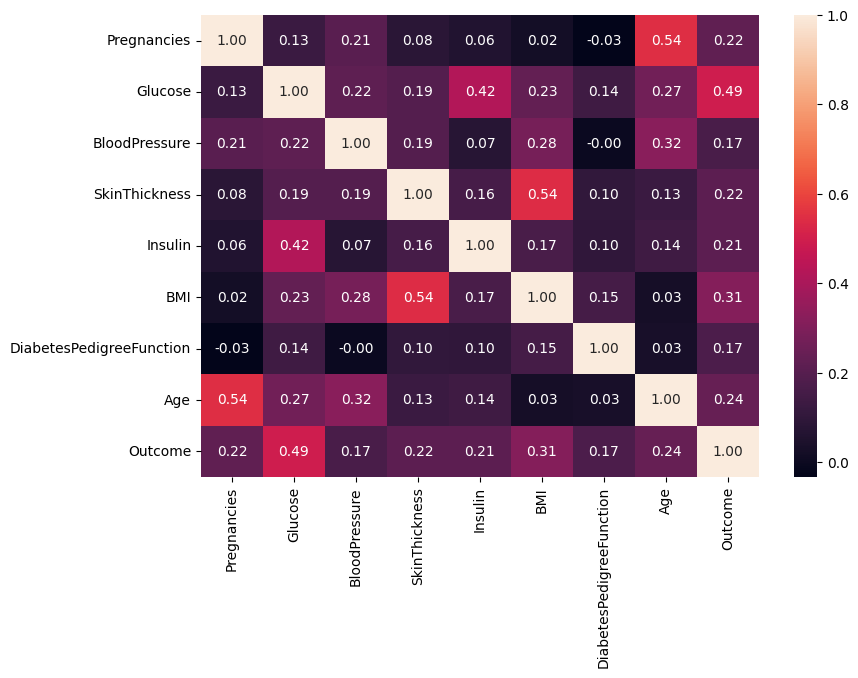

In [3]:
print(diabetes['Outcome'].value_counts())

mat.figure(figsize=(9, 6))
sea.heatmap(diabetes.corr(), annot=True, fmt='.2f')
mat.show()

Glucose has the strongest positive correlation with Outcome (0.49). BMI also has a positive correlation (0.31). There are more negative cases (500) than positive ones (268), so accuracy alone may be misleading.

#### 3. Split the dataset into labels and features.

In [4]:
X = diabetes.drop(columns='Outcome')
y = diabetes['Outcome']

X.shape, y.shape

((768, 8), (768,))

#### 4. Split the dataset into training and test sets (80% and 20%).

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=17
)

print('Train:', len(X_train), 'Test:', len(X_test))

Train: 614 Test: 154


#### 5. Build a decision tree regressor with some parameters for max depth and min samples, and a criterion of your choice (e.g. squared_error or absolute_error).

In [6]:
model = DecisionTreeRegressor(
    max_depth=4,
    min_samples_leaf=10,
    criterion='squared_error',
    random_state=17
)

model.fit(X_train, y_train)

,"criterion criterion: {""squared_error"", ""friedman_mse"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in the half mean Poisson deviance to find splits... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",4
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",10
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",17
,"max_lea

#### 6. Provide predictions for test set.

In [7]:
scores = model.predict(X_test)
predictions = (scores >= 0.5).astype(int)

pd.DataFrame({
    'Actual': y_test.values,
    'Score': scores,
    'Predicted': predictions
}).head(10).round(2)

,Actual,Score,Predicted
0,0,0.07,0
1,1,0.84,1
2,0,0.09,0
3,0,0.07,0
4,0,0.21,0
5,0,0.55,1
6,0,0.07,0
7,1,0.93,1
8,1,0.93,1
9,1,0.52,1


#### 7. Evaluate results.

In [8]:
print(metrics.confusion_matrix(y_test, predictions))

print('Accuracy:', round(metrics.accuracy_score(y_test, predictions), 2))
print('Precision:', round(metrics.precision_score(y_test, predictions), 2))
print('Recall:', round(metrics.recall_score(y_test, predictions), 2))
print('F1:', round(metrics.f1_score(y_test, predictions), 2))
print('AUC:', round(metrics.roc_auc_score(y_test, scores), 2))

[[77 20]
 [19 38]]
Accuracy: 0.75
Precision: 0.66
Recall: 0.67
F1: 0.66
AUC: 0.74


#### 8. Visualize tree.

Use plot_tree to visualize the tree. You can use figsize inside of plt.figure to control the size of the visualization.



In [9]:
from sklearn.tree import plot_tree

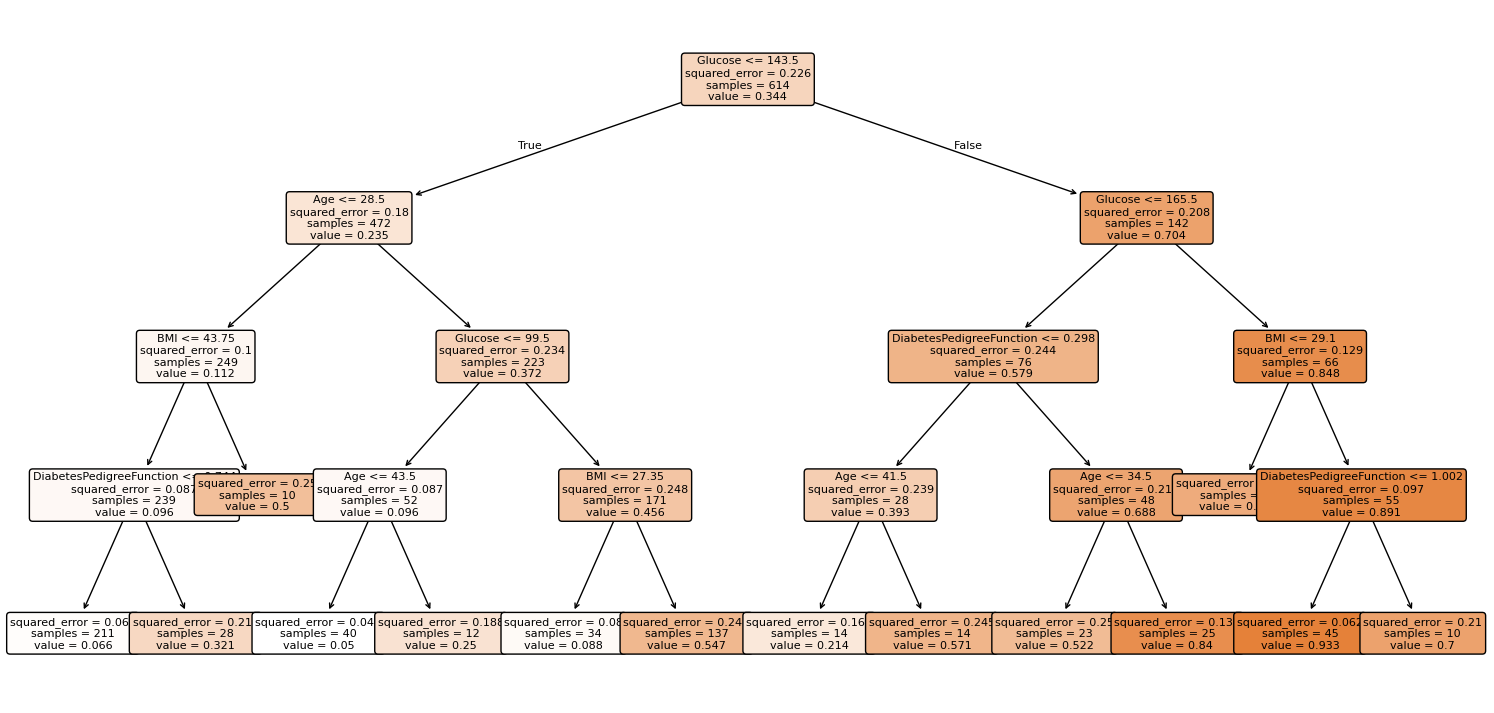

In [10]:
mat.figure(figsize=(19, 9))
plot_tree(model, feature_names=X.columns, filled=True, rounded=True, fontsize=8)
mat.show()

In [11]:
print('Depth:', model.get_depth())
print('Leaves:', model.get_n_leaves())

Depth: 4
Leaves: 14


# FINAL THOUGHTS
Answer the following questions:
- What is the possible benefit of using a regressor instead of a classifier?
- What drawbacks can you imagine when using a regressor to complete a non-binary classification?
- Which metric do you need to optimize the model for? Accuracy, Precision, Recall, F1? Why?

A regressor gives a continuous score instead of just a class. This allows us to choose different thresholds depending on the task.

With multiple classes, averaging class numbers can produce values that don't represent any real class. We would also need a way to convert these values back into classes.

I would focus on Recall because missing a positive diabetes case could be more serious than a false alarm. However, Precision and F1 are also important to avoid too many false positives.